# Versuch05 – Explorative Datenanalyse

Dieses Notebook untersucht alle Messungen von **Versuch05** entlang der Arbeitspunkte bis Session 2 (01–08).

- **Für einen anderen Versuch `VERSUCH` ändern** (erste Code-Zelle). Der Rest läuft unverändert. Ordner, die mit dem Versuchsnamen beginnen, werden gemeinsam geladen (z. B. `Versuch03_Fairphone` und `Versuch03_iPhone` für `Versuch03`).
- Eine Übersicht aller Messungen (Geräte, Startzeiten, Duplikate) steht in `00_Metadaten_Geraete.ipynb`.

In [1]:
import hashlib, re, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks, welch
warnings.filterwarnings('ignore')   # hide library deprecation warnings so the outputs stay readable

# Path to the raw data – the only line you need to change on another computer
DATA_ROOT = Path('/Users/majasmereczynska/Documents/Industrial AI/IPR_Daten_neu/data/Hybridachse')
# Which Versuch this notebook analyses – change this line to reuse the notebook for another one
VERSUCH = 'Versuch05'

# Figures are saved next to the notebook, prefixed with the Versuch (e.g. V05_...)
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
PREFIX = VERSUCH.replace('Versuch', 'V')

# Plot style: fixed colours in a fixed order (repeat 01 = blue, 02 = orange, 03 = green),
# light grid, no box around the plot
C = ['#2a78d6', '#eb6834', '#1baf7a']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'font.size': 9, 'legend.frameon': False})
pd.set_option('display.width', 200, 'display.max_columns', 30)

In [2]:
# Helper functions – used by the sections below

# The two phones name the same sensor file differently (Android 'Linear Acceleration.csv',
# iOS 'Linear Accelerometer.csv'). Map every file name to one short key.
SENSOR = {'Accelerometer': 'acc', 'Linear Acceleration': 'linacc', 'Linear Accelerometer': 'linacc',
          'Gyroscope': 'gyro', 'Magnetometer': 'mag', 'Barometer': 'baro',
          'Location': 'loc', 'Proximity': 'prox'}


def load(folder):
    """Load one recording: device, START/PAUSE events and all sensor tables.
    3-axis sensors get the columns t, x, y, z (the original names differ per phone)."""
    meta = pd.read_csv(folder / 'meta/device.csv').set_index('property')['value']
    # Short display name: 'Versuch04_iPhone_01' -> 'iPhone_01', 'Alle Sensoren 2024-12-09 11-50-01' -> 'iPhone 11-50-01'
    name = re.sub(r'^Versuch\d+_', '', folder.name).replace('Alle Sensoren ', 'iPhone ').replace('2024-12-09 ', '').replace('iPhone iPhone', 'iPhone')
    m = {'name': name, 'dev': 'IP' if 'iPhone' in meta['deviceModel'] else 'FP',
         'device': meta['deviceModel'], 'events': pd.read_csv(folder / 'meta/time.csv'), 'sensors': {}}
    for f in sorted(folder.glob('*.csv')):
        df = pd.read_csv(f)
        if df.shape[1] == 4:                       # time + 3 axes -> unify the column names
            df.columns = ['t', 'x', 'y', 'z']
        else:                                      # e.g. barometer, location: only rename the time column
            df = df.rename(columns={df.columns[0]: 't'})
        m['sensors'][SENSOR[f.stem]] = df
    return m


def load_versuch(versuch):
    """Load all recordings of a Versuch. A recording = a folder that contains meta/time.csv.
    All top-level folders starting with the Versuch name are searched, so 'Versuch03' loads
    both 'Versuch03_Fairphone' and 'Versuch03_iPhone'.
    Byte-identical copies (same Accelerometer.csv) are skipped – some folders in the raw data
    are exported twice; if a copy is mislabelled (folder says Fairphone, data is iPhone),
    the correctly named one is kept."""
    D, seen = {}, {}
    tfs = [tf for top in sorted(DATA_ROOT.glob(versuch + '*')) if top.is_dir() for tf in sorted(top.glob('**/meta/time.csv'))]
    for tf in tfs:
        folder = tf.parent.parent
        m = load(folder)
        h = hashlib.md5((folder / 'Accelerometer.csv').read_bytes()).hexdigest()
        name_ok = ('iphone' in m['name'].lower() or 'ip_' in m['name'].lower()) == (m['dev'] == 'IP')
        if h in seen:
            if name_ok and not seen[h][1]:          # replace the mislabelled copy
                del D[seen[h][0]]
            else:
                print('Duplikat übersprungen:', m['name'])
                continue
        seen[h] = (m['name'], name_ok)
        D[m['name']] = m
    return D


def drive_phases(m):
    """When is the carriage moving? Returns t, vibration envelope and a list of (start, end).
    1. High-pass the linear acceleration at 5 Hz: keeps the drive vibration, removes slow drift.
    2. Rolling median of the magnitude over 0.5 s = smooth 'vibration envelope'
       (median, not mean, so a single jerk is not counted as driving).
    3. 'Moving' = envelope clearly above the quietest 5 % of this recording (3x, at least +0.01 m/s²).
       Relative to each recording, so it works for the noisier Fairphone and the quieter iPhone.
    4. Keep stretches of at least 0.5 s.
    The factors are heuristics – check the grey segments in the overview plot."""
    df = m['sensors']['linacc']
    t, a = df['t'].values, df[['x', 'y', 'z']].values
    fs = 1 / np.median(np.diff(t))
    hp = sosfiltfilt(butter(4, 5, 'hp', fs=fs, output='sos'), a, axis=0)   # forward+backward = no time shift
    env = pd.Series(np.linalg.norm(hp, axis=1)).rolling(int(fs * 0.5), center=True).median().bfill().ffill().values
    quiet = np.percentile(env, 5)
    on = env > max(3 * quiet, quiet + 0.01)
    edges = np.diff(np.r_[0, on.astype(int), 0])          # +1 where a phase starts, -1 where it ends
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0] - 1
    segs = [(t[s], t[e]) for s, e in zip(starts, ends) if t[e] - t[s] >= 0.5]
    return t, env, segs


def impulses(m, thr=2.0):
    """Braking/starting jerks: peaks of |linear acceleration| above thr m/s², at least 0.3 s apart
    (so one jerk with some ringing counts once). Returns peak times and amplitudes."""
    df = m['sensors']['linacc']
    t, am = df['t'].values, np.linalg.norm(df[['x', 'y', 'z']].values, axis=1)
    pk, _ = find_peaks(am, height=thr, distance=int(0.3 / np.median(np.diff(t))))
    return t[pk], am[pk]


def spectrum_drive(m, axis):
    """Frequency spectrum (Welch PSD) of the raw acceleration during steady travel only:
    1 s is cut off both ends of every travel phase, otherwise the start/stop jerks dominate."""
    df = m['sensors']['acc']
    t, fs = df['t'].values, 1 / np.median(np.diff(df['t'].values))
    parts = [df[axis].values[(t > a + 1) & (t < b - 1)] for a, b in drive_phases(m)[2] if b - a > 3]
    if not parts:                                         # carriage never moved -> no spectrum
        return None, None
    x = np.concatenate([p - p.mean() for p in parts])     # remove gravity (mean) of each piece
    return welch(x, fs=fs, nperseg=int(fs * 2))           # 2 s windows -> 0.5 Hz resolution


def main_axis(m):
    """Axis with the most motion – usually y (travel direction) if the phone rides on the carriage."""
    la = m['sensors']['linacc']
    return max('xyz', key=lambda a: la[a].std())

In [3]:
# Load all recordings of this Versuch into a dict: name -> recording
D = load_versuch(VERSUCH)
list(D)

['FP_01', 'FP_02', 'FP_03', 'IP_01', 'IP_02', 'IP_03']

## 01 Datensatz beschreiben

Welche Messungen, Geräte und Sensordateien gibt es, und wann wurde aufgenommen?

In [4]:
# One row per recording. The absolute start time comes from meta/time.csv: it is the only way to
# see which Fairphone and iPhone recordings ran at the same time. More than 2 START/PAUSE events
# means the recording was paused and restarted.
rows = []
for name, m in D.items():
    ev = m['events']
    rows.append({'Messung': name, 'Gerät': m['device'],
                 'Start (Uhrzeit)': ev['system time text'].iloc[0][11:23],
                 'Dauer (s)': round(ev['experiment time'].iloc[-1], 1),
                 'START/PAUSE-Ereignisse': len(ev),
                 'Sensoren': ', '.join(m['sensors'])})
pd.DataFrame(rows).set_index('Messung')

,Gerät,Start (Uhrzeit),Dauer (s),START/PAUSE-Ereignisse,Sensoren
Messung,,,,,
FP_01,FP4,12:22:29.215,58.3,2,"acc, gyro, linacc, mag"
FP_02,FP4,12:25:53.922,45.6,2,"acc, gyro, linacc, mag"
FP_03,FP4,12:27:35.640,52.1,4,"acc, gyro, linacc, mag"
IP_01,"iPhone13,2",12:22:29.926,54.3,2,"acc, baro, gyro, linacc, loc, mag, prox"
IP_02,"iPhone13,2",12:25:50.644,49.8,2,"acc, baro, gyro, linacc, loc, mag, prox"
IP_03,"iPhone13,2",12:27:38.922,45.1,2,"acc, baro, gyro, linacc, loc, mag, prox"


**Befund 01**

- **6 Messungen:** Fairphone FP_01–03 (Fairphone 4) und iPhone IP_01–03 (iPhone 12).
- **Paarweise gleichzeitig aufgenommen** (laut Startzeit):
  - FP_01/IP_01 um 12:22:29, 0,7 s Versatz;
  - FP_02/IP_02 um 12:25:50/53, 3,3 s Versatz;
  - FP_03/IP_03 um 12:27:35/38, 3,3 s Versatz.
- **Sensordateien:** Fairphone 4 (acc, gyro, linacc, mag), iPhone 7 (zusätzlich Barometer, Location, Proximity).
- **FP_03 wurde einmal unterbrochen** (4 START/PAUSE-Ereignisse, siehe 05).
- Keine Duplikate.

## 02 Messungen charakterisieren

Abtastraten, Zeitstruktur, Wertebereiche und Lage der Handys.

In [5]:
# Sampling rate = 1 / median time step (the median ignores a few long gaps).
# Largest gap = longest time between two samples; reveals pauses or dropped samples.
rows = []
for name, m in D.items():
    for s in ['acc', 'linacc', 'gyro', 'mag']:
        dt = np.diff(m['sensors'][s]['t'].values)
        rows.append({'Messung': name, 'Sensor': s, 'fs (Hz)': round(1 / np.median(dt), 1),
                     'größte Lücke (ms)': round(dt.max() * 1000, 1)})
pd.DataFrame(rows).pivot(index='Messung', columns='Sensor')

fs (Hz)                      größte Lücke (ms)                     
Sensor      acc   gyro linacc    mag               acc   gyro linacc    mag
Messung                                                                    
FP_01     426.7  426.7  213.4  100.0               2.4    2.4    4.7   10.0
FP_02     426.7  426.7  213.4  100.0               2.4    2.3    4.7   10.0
FP_03     426.7  426.7  213.4  100.0              34.5  137.7  142.4  203.5
IP_01      99.8   99.8   99.8   99.8              10.0   10.0   10.0   10.0
IP_02      99.8   99.8   99.8   99.8              10.0   10.0   10.0   10.0
IP_03      99.8   99.8   99.8   99.8              10.0   10.0   10.0   10.0

In [6]:
# Value ranges per device and sensor: smallest minimum and largest maximum over all axes and recordings
rows = []
for name, m in D.items():
    for s, unit in [('acc', 'm/s²'), ('linacc', 'm/s²'), ('gyro', 'rad/s'), ('mag', 'µT')]:
        v = m['sensors'][s][['x', 'y', 'z']]
        rows.append({'Gerät': m['dev'], 'Sensor': f'{s} ({unit})', 'min': v.min().min(), 'max': v.max().max()})
pd.DataFrame(rows).groupby(['Gerät', 'Sensor']).agg({'min': 'min', 'max': 'max'}).round(2)

min     max
Gerät Sensor                       
FP    acc (m/s²)     -11.08    0.73
      gyro (rad/s)    -0.04    0.03
      linacc (m/s²)   -0.80    0.71
      mag (µT)       -85.43  131.79
IP    acc (m/s²)     -10.08    6.54
      gyro (rad/s)    -0.03    0.01
      linacc (m/s²)   -7.50    6.49
      mag (µT)      -173.75  100.43

In [7]:
# The phones at rest: samples at least 1 s away from any travel phase.
# - Lage: mean gravity vector (g_x, g_y, g_z) = how the phone lies / is tilted
# - Ruhe-Rauschen: standard deviation of the raw acceleration at rest (mm/s²) = sensor noise
# - Gyro-Offset z: mean rotation rate at rest (should be 0; anything else is sensor bias)
rows = []
for name, m in D.items():
    _, _, segs = drive_phases(m)
    acc, gyro = m['sensors']['acc'], m['sensors']['gyro']
    rest_a = np.ones(len(acc), bool); rest_g = np.ones(len(gyro), bool)
    for a, b in segs:
        rest_a &= ~acc['t'].between(a - 1, b + 1).values
        rest_g &= ~gyro['t'].between(a - 1, b + 1).values
    A = acc[rest_a]
    rows.append({'Messung': name, 'Gerät': m['dev'], 'Ruhe-Samples': int(rest_a.sum()),
                 'g_x': A['x'].mean(), 'g_y': A['y'].mean(), 'g_z': A['z'].mean(),
                 'Ruhe-Rauschen x (mm/s²)': 1000 * A['x'].std(), 'Ruhe-Rauschen y (mm/s²)': 1000 * A['y'].std(),
                 'Ruhe-Rauschen z (mm/s²)': 1000 * A['z'].std(),
                 'Gyro-Offset z (mrad/s)': 1000 * gyro.loc[rest_g, 'z'].mean()})
pd.DataFrame(rows).set_index('Messung').round(3)

,Gerät,Ruhe-Samples,g_x,g_y,g_z,Ruhe-Rauschen x (mm/s²),Ruhe-Rauschen y (mm/s²),Ruhe-Rauschen z (mm/s²),Gyro-Offset z (mrad/s)
Messung,,,,,,,,,
FP_01,FP,3935,-0.066,0.132,-9.959,12.786,11.031,11.340,-2.120
FP_02,FP,935,-0.064,0.136,-9.958,12.918,10.951,11.881,-1.928
FP_03,FP,3702,-0.064,0.134,-9.961,12.739,11.151,11.078,-2.013
IP_01,IP,483,0.030,0.052,-9.788,4.348,3.971,5.353,-0.102
IP_02,IP,597,0.030,0.053,-9.790,4.383,4.249,5.312,0.031
IP_03,IP,292,0.031,0.051,-9.789,4.444,3.906,5.739,0.019


**Befund 02**

- **Abtastraten:**
  - Fairphone: Beschleunigung und Gyroskop ≈ 427 Hz, lineare Beschleunigung ≈ 213 Hz, Magnetometer 100 Hz.
  - iPhone: alles ≈ 100 Hz.
- **Messdauern:** 45–58 s.
- **Zeitstruktur:** Die Zeitachse ist regelmäßig. Die einzige größere Lücke (35–204 ms) liegt in FP_03 und kommt von der Aufnahmepause.
- **Wertebereiche:**
  - Lineare Beschleunigung: Fairphone −0,8 … 0,7 m/s², iPhone −7,5 … 6,5 m/s². Das iPhone erfährt starke Rucke, das Fairphone nicht.
  - Gyroskop: unter 0,04 rad/s, also kaum Drehung.
- **Lage (Schwerkraftvektor in Ruhe):** Beide Handys liegen flach (g_z ≈ −9,96 bzw. −9,79 m/s²). Die Neigung ist in allen drei Wiederholungen gleich (Fairphone g_x ≈ −0,065, iPhone ≈ +0,03 m/s²).
- **Ruhe-Rauschen** (Standardabweichung der Beschleunigung in Ruhe, letzte Tabelle):
  - Fairphone 11–13 mm/s², iPhone 4–6 mm/s².
  - Das Fairphone rauscht also etwa 2–3× stärker.
- **Gyro-Offset z** (mittlere Drehrate in Ruhe, sollte 0 sein):
  - Fairphone ≈ −2 mrad/s, also ein leichter Sensor-Offset.
  - iPhone ≈ 0 (−0,10 … +0,03 mrad/s).
- **Kurze Ruhe beim iPhone:** Es gibt nur 292–597 Ruhe-Samples (3–6 s), daher sind seine Ruhewerte etwas unsicherer.

## 03 Signale visualisieren

**Abb. 1:** Pro Messung links |lineare Beschleunigung| mit den erkannten Fahrphasen (grau) und Impulsen > 2 m/s² (Punkte), rechts der Betrag des Magnetfelds als grober Positionsindikator.

**Abb. 2:** Frequenzspektrum während der gleichmäßigen Fahrt, je Gerät.

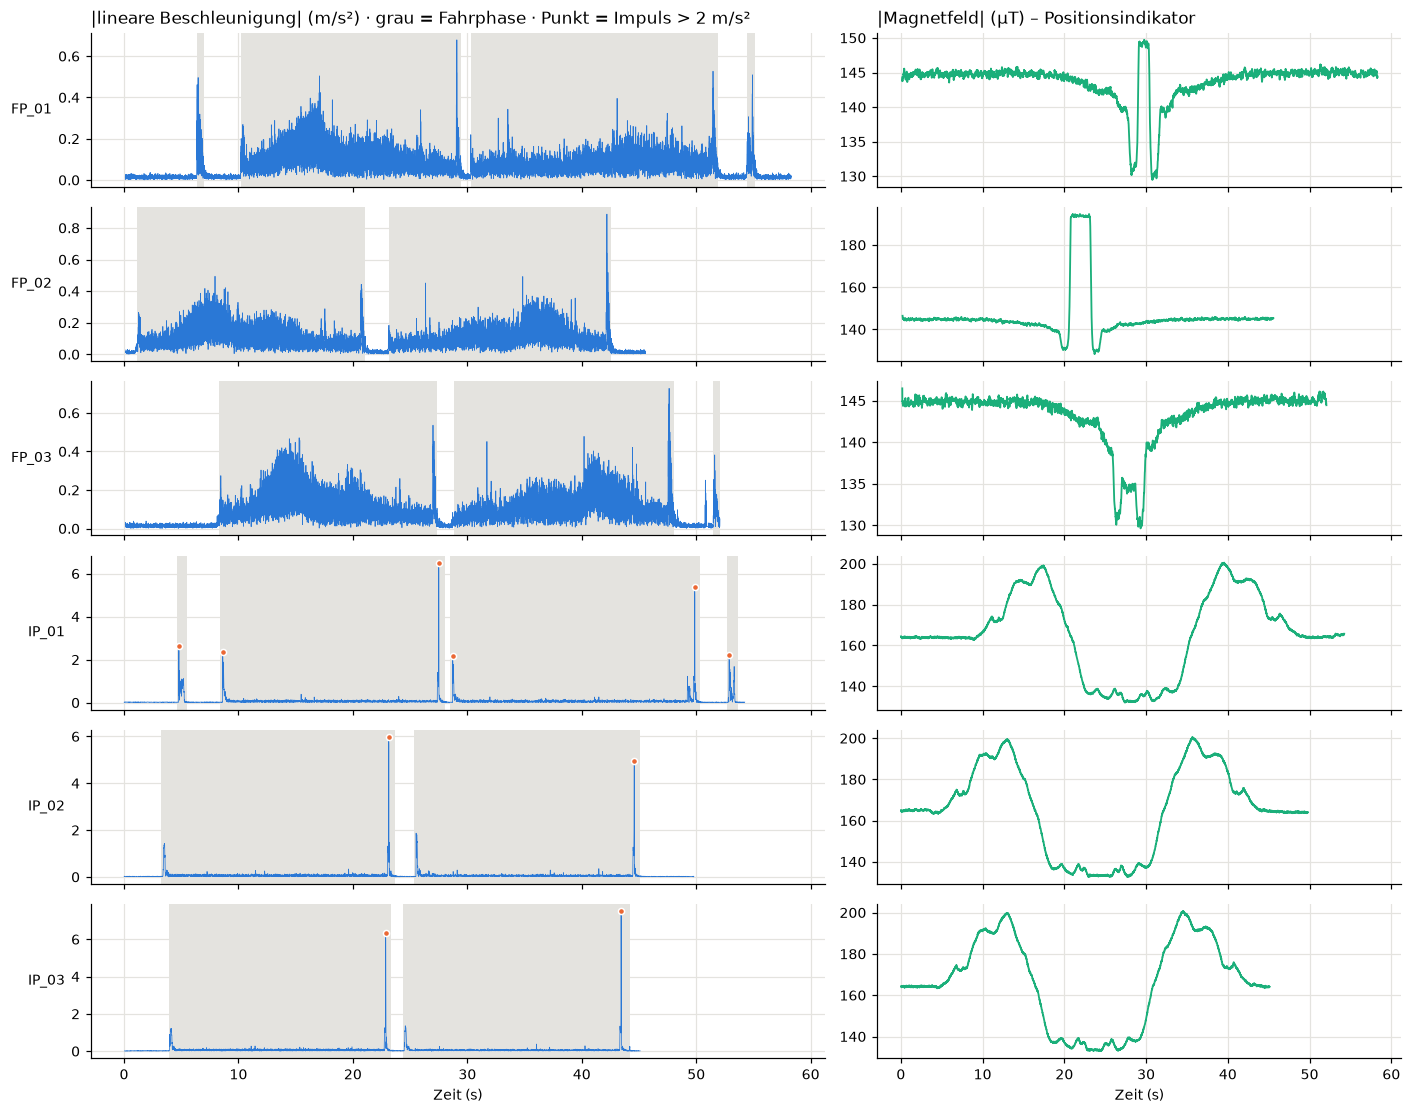

In [8]:
# Fig. 1 – overview, one row per recording, shared time axis
fig, axs = plt.subplots(len(D), 2, figsize=(13, 1.7 * len(D)), sharex=True, squeeze=False,
                        gridspec_kw={'width_ratios': [1.4, 1]})
for i, (name, m) in enumerate(D.items()):
    la = m['sensors']['linacc']
    t, env, segs = drive_phases(m)
    for a, b in segs:                                           # grey = detected travel phase
        axs[i, 0].axvspan(a, b, color='#e4e3df', lw=0)
    axs[i, 0].plot(la['t'], np.linalg.norm(la[['x', 'y', 'z']].values, axis=1), color=C[0], lw=0.5)
    pt, pa = impulses(m)
    axs[i, 0].plot(pt, pa, 'o', ms=4, color=C[1], mec='white')  # orange dots = impulses
    axs[i, 0].set_ylabel(name, rotation=0, ha='right', va='center')
    mg = m['sensors']['mag']                                    # magnetic field magnitude = position proxy
    axs[i, 1].plot(mg['t'], np.linalg.norm(mg[['x', 'y', 'z']].values, axis=1), color=C[2], lw=1.2)
axs[0, 0].set_title('|lineare Beschleunigung| (m/s²) · grau = Fahrphase · Punkt = Impuls > 2 m/s²', loc='left')
axs[0, 1].set_title('|Magnetfeld| (µT) – Positionsindikator', loc='left')
for ax in axs[-1]:
    ax.set_xlabel('Zeit (s)')
fig.tight_layout(); fig.savefig(FIG / f'{PREFIX}_1_uebersicht.png', dpi=150)

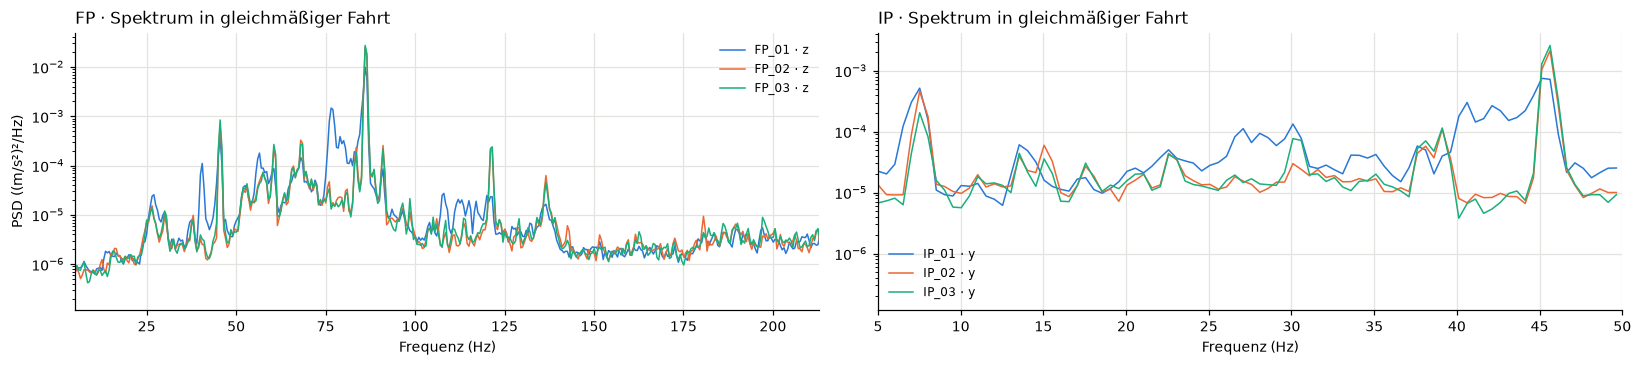

In [9]:
# Fig. 2 – spectrum during steady travel, one panel per device (Fairphone samples at 427 Hz,
# iPhone at 100 Hz, so their frequency ranges differ and must not share one axis).
# Each recording is shown on its main axis. Log scale: spectral lines stand out by orders of magnitude.
devs = sorted({m['dev'] for m in D.values()})
fig, axs = plt.subplots(1, len(devs), figsize=(13 if len(devs) == 1 else 15, 3.4), squeeze=False)
for ax, dev in zip(axs[0], devs):
    for i, (name, m) in enumerate((n, m) for n, m in D.items() if m['dev'] == dev):
        ax_name = main_axis(m)
        f, P = spectrum_drive(m, ax_name)
        if f is None:                                         # no travel phase -> nothing to plot
            continue
        ax.semilogy(f, P, color=C[i % 3], lw=1, label=f'{name} · {ax_name}')
    ax.set_xlim(5, 213 if dev == 'FP' else 50); ax.set_xlabel('Frequenz (Hz)'); ax.legend(fontsize=8)
    ax.set_title(f'{dev} · Spektrum in gleichmäßiger Fahrt', loc='left')
axs[0, 0].set_ylabel('PSD ((m/s²)²/Hz)')
fig.tight_layout(); fig.savefig(FIG / f'{PREFIX}_2_spektrum.png', dpi=150)

**Befund 03**

- **Abb. 1, iPhone:**
  - Das Magnetfeld folgt der ganzen Fahrt: ≈ 165 µT → bis ≈ 200 µT → Plateau ≈ 135 µT → zurück. Das iPhone **fuhr auf dem Schlitten** mit.
  - Impulse treten nur beim Anfahren und Bremsen auf.
- **Abb. 1, Fairphone:**
  - Das Magnetfeld bleibt bei ≈ 145 µT, abgesehen von einem kurzen Einbruch bzw. Sprung in der Mitte der Messung (Wendepunkt).
  - Die Vibration steigt in zwei Bögen an (Hin- und Rückfahrt) und ist am stärksten, wenn der Schlitten nahe ist.
  - *Interpretation:* Das Fairphone lag **ortsfest auf dem Maschinengestell**, nahe dem Ende des Fahrwegs.
- **Abb. 2, Fairphone:**
  - Schmale Linien bei **86 Hz** (stärkste), **45,5 Hz** und **121,6 Hz**, dazu mehrere kleinere Spitzen zwischen 60 und 80 Hz.
  - FP_01 hat zusätzlich eine Spitze bei ≈ 77 Hz.
- **Abb. 2, iPhone:**
  - Stärkste Linie bei **45,6 Hz**, dazu eine Spitze bei 7,5 Hz.
  - 86 Hz kann das iPhone nicht erfassen (100 Hz Abtastrate → höchstens 50 Hz messbar). Es erscheint gespiegelt bei ≈ 14 Hz (Aliasing).

## 04 Messungen vergleichen

Für jede Messung dieselben acht Kennzahlen (Merkmale), damit die Wiederholungen direkt vergleichbar sind.

In [10]:
# Features per recording:
# - Fahrzeit: total time the carriage moves; Fahrabschnitte: travel phases > 2 s
#   (2 = continuous out and back, more = stops in between)
# - Fahr-Vibration: median of the vibration envelope while moving
# - Impulse / max |a|: number and strength of the braking/starting jerks
# - dominante Frequenz: strongest spectral peak above 20 Hz during steady travel
#   (below 20 Hz is the slow motion of the carriage itself)
# - |B|-Spanne: range of the magnetic field = how far the phone moves past steel parts
rows = []
for name, m in D.items():
    t, env, segs = drive_phases(m)
    moving = np.zeros(len(t), bool)
    for a, b in segs:
        moving |= (t >= a) & (t <= b)
    pt, pa = impulses(m)
    f, P = spectrum_drive(m, main_axis(m))
    dom = round(f[f > 20][P[f > 20].argmax()], 1) if f is not None else np.nan
    mg = m['sensors']['mag']; B = np.linalg.norm(mg[['x', 'y', 'z']].values, axis=1)
    la = m['sensors']['linacc']
    rows.append({'Messung': name, 'Gerät': m['dev'],
                 'Dauer (s)': round(t[-1], 1),
                 'Fahrzeit (s)': round(moving.mean() * t[-1], 1),
                 'Fahrabschnitte': sum(b - a > 2 for a, b in segs),
                 'Fahr-Vibration (m/s²)': round(np.median(env[moving]), 3) if moving.any() else np.nan,
                 'Impulse > 2 m/s²': len(pt),
                 'max |a| (m/s²)': round(np.linalg.norm(la[['x', 'y', 'z']].values, axis=1).max(), 1),
                 'dominante Frequenz (Hz)': dom,
                 '|B|-Spanne (µT)': round(B.max() - B.min(), 1)})
feat = pd.DataFrame(rows).set_index('Messung')
feat

,Gerät,Dauer (s),Fahrzeit (s),Fahrabschnitte,Fahr-Vibration (m/s²),Impulse > 2 m/s²,max |a| (m/s²),dominante Frequenz (Hz),|B|-Spanne (µT)
Messung,,,,,,,,,
FP_01,FP,58.3,42.2,2,0.082,0,0.7,86.0,20.3
FP_02,FP,45.6,39.5,2,0.102,0,0.9,86.0,66.3
FP_03,FP,52.1,39.1,2,0.112,0,0.7,86.0,16.9
IP_01,IP,54.2,43.4,2,0.051,6,6.5,45.1,68.6
IP_02,IP,49.8,40.2,2,0.044,2,6.0,45.6,68.1
IP_03,IP,45.1,39.3,2,0.048,2,7.5,45.6,67.8


**Befund 04**

- **Alle 6 Messungen:** 2 Fahrabschnitte (durchgehend hin und zurück) und 39–43 s Fahrzeit.
- **Fairphone:**
  - 0 Impulse, max |a| 0,7–0,9 m/s².
  - Fahr-Vibration 0,08–0,11 m/s².
  - Dominante Frequenz 86 Hz.
- **iPhone:**
  - 2–6 Impulse (Anfahren und Bremsen), max |a| 6,0–7,5 m/s².
  - Fahr-Vibration 0,044–0,051 m/s².
  - Dominante Frequenz 45,1–45,6 Hz.
- **|B|-Spanne:**
  - iPhone in allen drei Messungen ≈ 68 µT.
  - Fairphone 17–20 µT, nur **FP_02 hat 66 µT**, wegen des Sprungs am Wendepunkt.
- *Interpretation:* Die Unterschiede zwischen Fairphone und iPhone kommen vor allem vom **Ablageort** (Gestell vs. Schlitten). Gerät und Ort lassen sich in diesem Versuch aber nicht trennen, weil es keine Messung mit beiden Handys am selben Ort gibt.

## 05 Datenqualität prüfen

Fehlende Werte, konstante Spalten, doppelte Zeitstempel und Aufnahmepausen.

In [11]:
# Check every file; only files with a problem are shown
rows = []
for name, m in D.items():
    for s, df in m['sensors'].items():
        num = df.drop(columns='t')
        rows.append({'Messung': name, 'Sensor': s, 'Zeilen': len(df),
                     'fehlende Werte': int(num.isna().sum().sum()),
                     'konstante Spalten': ', '.join(c for c in num if num[c].nunique() <= 1),   # no information
                     'doppelte Zeitstempel': int(df['t'].duplicated().sum())})
q = pd.DataFrame(rows)
q[(q['fehlende Werte'] > 0) | (q['konstante Spalten'] != '') | (q['Zeilen'] < 10) | (q['doppelte Zeitstempel'] > 0)]

,Messung,Sensor,Zeilen,fehlende Werte,konstante Spalten,doppelte Zeitstempel
16,IP_01,loc,54,50,,0
18,IP_01,prox,1,0,Distance (cm),0
23,IP_02,loc,49,52,Direction (°),0
25,IP_02,prox,1,0,Distance (cm),0
30,IP_03,loc,47,45,,0
32,IP_03,prox,3,0,,0


In [12]:
# Recordings that were paused and restarted (more than one START/PAUSE pair) -> time gap in the data
for name, m in D.items():
    if len(m['events']) > 2:
        print(name); print(m['events'][['event', 'experiment time', 'system time text']].to_string(index=False))

FP_03
event  experiment time                  system time text
START         0.000000 2024-12-09 12:27:35.640 UTC+01:00
PAUSE        50.906711 2024-12-09 12:28:26.547 UTC+01:00
START        50.906711 2024-12-09 12:28:27.767 UTC+01:00
PAUSE        52.071386 2024-12-09 12:28:28.932 UTC+01:00


**Befund 05**

- **Bewegungssensoren:** keine fehlenden Werte und keine doppelten Zeitstempel in acc, linacc, gyro und mag.
- **iPhone-Zusatzsensoren kaum brauchbar:**
  - `loc` (Location) hat 45–52 fehlende Werte (Velocity, Direction). GPS ist in der Halle ohnehin ohne Aussage.
  - `prox` (Proximity) hat nur 1–3 Zeilen und ist meist konstant.
- **FP_03:** Die Aufnahme wurde nach 50,9 s pausiert und 1,2 s später neu gestartet. Daraus entstehen die Lücken aus 02. Die letzten ≈ 1,2 s sollten vor weiteren Analysen abgeschnitten werden.
- **FP_02:** beginnt fast sofort mit der Fahrt (erste Bewegung ≈ 1 s) und hat deshalb nur ≈ 2 s Ruhe.
- **Ungewöhnliche Werte:**
  - Die Impulse beim iPhone (bis 7,5 m/s²) sind echte Brems- und Anfahrrucke, **keine Messfehler**.
  - Ungeklärt sind die **Sprünge im Magnetfeld** des Fairphones (am deutlichsten in FP_02): ein nahes Stahlteil oder ein Sensoreffekt?

## 06 Normalverhalten charakterisieren

Wie ähnlich sind die Wiederholungen? Grundlage: Mittelwert und Variationskoeffizient (CV = Standardabweichung / Mittelwert) der Merkmale sowie die Vibrationshüllkurven, ausgerichtet auf die erste Bewegung (**Abb. 3**).

In [13]:
# Small CV (a few %) = repeats behave the same = stable reference for 'normal'
cols = ['Fahrzeit (s)', 'Fahrabschnitte', 'Fahr-Vibration (m/s²)', 'Impulse > 2 m/s²', 'max |a| (m/s²)', '|B|-Spanne (µT)']
g = feat.groupby('Gerät')[cols]
pd.concat({'Mittelwert': g.mean().round(3), 'CV (%)': (100 * g.std() / g.mean()).round(1)}, axis=1).T

Gerät                                 FP      IP
Mittelwert Fahrzeit (s)           40.267  40.967
           Fahrabschnitte          2.000   2.000
           Fahr-Vibration (m/s²)   0.099   0.048
           Impulse > 2 m/s²        0.000   3.333
           max |a| (m/s²)          0.767   6.667
           |B|-Spanne (µT)        34.500  68.167
CV (%)     Fahrzeit (s)            4.200   5.300
           Fahrabschnitte          0.000   0.000
           Fahr-Vibration (m/s²)  15.500   7.400
           Impulse > 2 m/s²          NaN  69.300
           max |a| (m/s²)         15.100  11.500
           |B|-Spanne (µT)        80.000   0.600

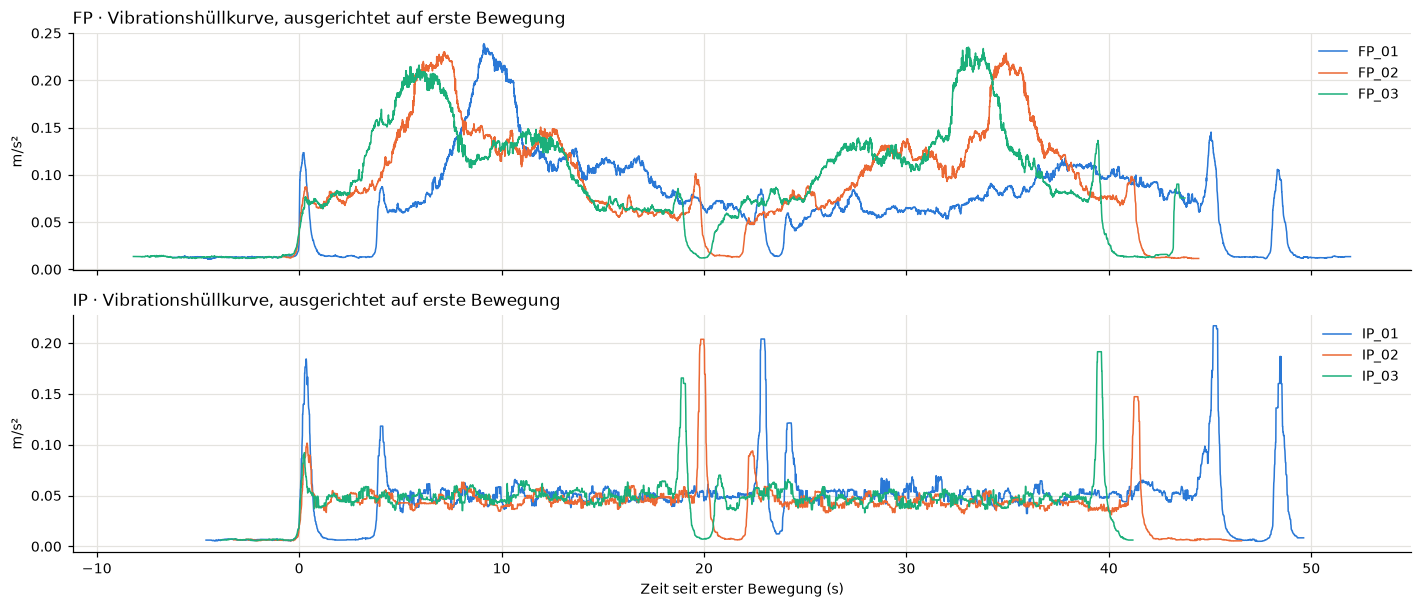

In [14]:
# Fig. 3 – vibration envelopes of the repeats, one panel per device. Shifted so t = 0 is the first
# movement: recordings start at different times before the carriage moves, so comparing on
# recording time would hide how similar the repeats are.
fig, axs = plt.subplots(len(devs), 1, figsize=(13, 2.8 * len(devs)), sharex=True, squeeze=False)
for ax, dev in zip(axs[:, 0], devs):
    for i, (name, m) in enumerate((n, m) for n, m in D.items() if m['dev'] == dev):
        t, env, segs = drive_phases(m)
        t0 = segs[0][0] if segs else 0               # no movement: keep the recording time
        ax.plot(t - t0, env, color=C[i % 3], lw=1, label=name)
    ax.set_title(f'{dev} · Vibrationshüllkurve, ausgerichtet auf erste Bewegung', loc='left')
    ax.set_ylabel('m/s²'); ax.legend(loc='upper right')
axs[-1, 0].set_xlabel('Zeit seit erster Bewegung (s)')
fig.tight_layout(); fig.savefig(FIG / f'{PREFIX}_3_normalverhalten.png', dpi=150)

**Befund 06**

- **iPhone sehr reproduzierbar:** CV Fahrzeit 5 %, Fahr-Vibration 7 %, |B|-Spanne 0,6 %. In Abb. 3 liegen die drei Hüllkurven nahezu übereinander.
- **Fairphone weniger gleichmäßig:**
  - Fahr-Vibration CV 15 %, |B|-Spanne CV 80 % (wegen FP_02).
  - In Abb. 3 ist die Form ähnlich, aber zeitlich versetzt. FP_01 zeigt einen kurzen Fehlstart.
  - *Interpretation:* Das ortsfeste Handy reagiert empfindlich auf Abstand und Geschwindigkeit des Schlittens.
- **Typischer Ablauf:** Ruhe → Anfahrruck → gleichmäßige Fahrt → Bremsruck, kurzer Halt am Ende → Rückfahrt → Bremsruck → Ruhe.
- **Natürliche Variation:** Zeit bis zur ersten Bewegung (1–8 s) und Länge der Ruhephasen.
- **Fazit:** Dieser Versuch ist eine gute Referenz für **durchgehende Fahrt**, mit dem iPhone auf dem Schlitten und dem Fairphone ortsfest.

## 07 Hypothesen

- **H1:** Die Vibration am ortsfesten Fairphone wächst mit der Nähe des Schlittens.
  - *Test:* Fairphone-Hüllkurve gegen das Magnetfeld des gleichzeitig laufenden iPhones (Position) auf gemeinsamer Uhrzeit auftragen (Startzeiten aus 01).
- **H2:** Die Linien bei 45,5 / 86 / 121,6 Hz hängen an der Antriebsdrehzahl.
  - *Test:* Das Verhältnis der Frequenzen bleibt in allen Messungen gleich, auch wenn sich die absoluten Werte leicht verschieben.
- **H3:** Die Magnetfeld-Sprünge des Fairphones kommen von einem Bauteil, an dem der Schlitten vorbeifährt.
  - *Test:* Sie sollten in jeder Messung zur gleichen Fahrposition auftreten (am Wendepunkt).

## 08 Offene Fragen

- Wo genau lag das Fairphone (Schiene, Gestell, welche Position)?
- Was war die Versuchsbedingung? Wurde an der Maschine etwas verändert?
- Woher kommen die Magnetfeld-Sprünge des Fairphones?
- Mit welcher Drehzahl lief der Akkuschrauber? Lief er immer gleich schnell?